In [ ]:
!pip install qiskit
!pip install qiskit-aer
!pip install matplotlib
!pip install pylatexenc
!pip install qiskit[visualization]
!pip install qiskit-ibm-runtime
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
import numpy as np


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 43.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 35.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 26.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 53.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 19.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [qiskit-ibm-runtime]


Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
{'0': 2000}


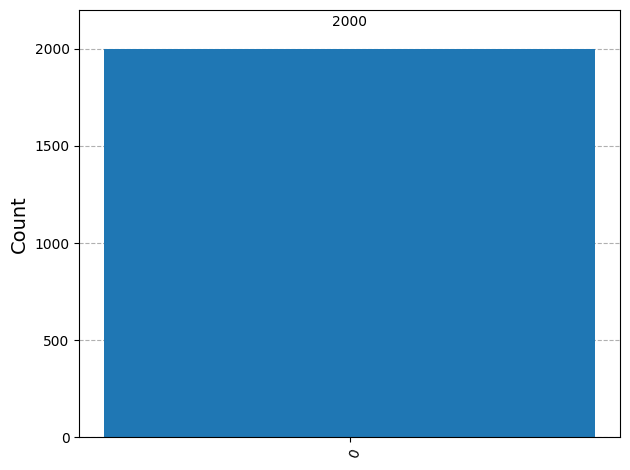

In [ ]:
#objective 1.1 Build the Mach–Zehnder interferometer circuit without a bomb and show that the output is
#deterministic.

def no_bomb():    #defining a function to implement no bomb experiment
  qc= QuantumCircuit(1,1)
  qc.h(0)   #hadamard acts as a perfect beam splitter
  qc.h(0)   #since there is no bomb no cnot gate will be present
  qc.measure(0,0)
  return qc

qc_1 = no_bomb()

qc_1.draw("mpl")

q_photon = QuantumCircuit(1)#this repesents our photon qubit
q_photon.h(0)
q_photon.h(0)
sv= Statevector(q_photon)
print(sv)

# Initialize the simulator and correct qc to qc_1
sim = AerSimulator()
result = sim.run(transpile(qc_1, sim), shots=2000).result()
counts = result.get_counts()
print(counts)
display(plot_histogram(counts))#this shows that qubit remains |0> as H.H=I


#This operation is purely deterministic as we are using two hadamard gates in series
#which converges to an identity operator or no gate at all. Output = input,
#Since this output can be written as a direct function of input
#it is deterministic operator



In [ ]:
#objective 1.2 Build the bomb-placement circuit and report the detection, explosion and inconclusive probabilities
#from simulation.

def circuit(bomb: bool):#defining bomb circuit as a function
  qc_2 = QuantumCircuit(2,2)
  qc_2.h(0)
  if bomb:
    qc_2.cx(0,1)#this cnot gate only acts if a bomb is present
  qc_2.h(0)#if a bomb isn't present this hadamard and the before one will become identity
  qc_2.measure([0,1], [0,1])
  return qc_2

results={}#this is variable where every result is stored
shots =10000
for bomb in [True, False]:
  qc_2 = circuit(bomb)
  sim = AerSimulator()
  result = sim.run(transpile(qc_2, sim), shots=shots).result()
  counts = result.get_counts()#this gets individual counts of each output(00,01,10,11)
  print(counts)#this prints the counts
  results[bomb] = counts


print("\nLive bomb breakdown (theory: 0.50 / 0.25 / 0.25):")
count_00 = results[True].get('00', 0)
count_01 = results[True].get('01', 0)
count_10 = results[True].get('10', 0)
count_11 = results[True].get('11', 0)

#if no bomb is present, operator will be identity output should be |00>
#|00> can also mean that photon took the upper path, meaning that we can't comment/inconclusive
#So no. of shots where we got no bomb present is no. of times where we got the output |00>
print(f"P(no bomb/inconclusive) = {count_00/shots}")

#if a bomb is present and it's detected without exploding
#since no explosion bomb qubit = 0 and since detected photon qubit 1
#but we need to write it as 01, instead of 10, as qiskit stores in reverse
print(f"P(detection) = {count_01/shots}")


#if an explosion happens then the second qubit will be 1, or acc to qiskit the first one
print(f"P(explosion) = {(count_11+ count_10)/shots}" )

{'10': 2513, '00': 2420, '11': 2494, '01': 2573}
{'00': 10000}

Live bomb breakdown (theory: 0.50 / 0.25 / 0.25):
P(no bomb/inconclusive) = 0.242
P(detection) = 0.2573
P(explosion) = 0.5007


In [ ]:
#Objective 1.3 Raise the interaction-free detection score above the 50% baseline, for example by tuning the
#rotation angle or by repeating the probe.
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import numpy as np

def chain_circuit(N, bomb):
  tita = np.pi/(2*N)
  qc= QuantumCircuit(3,3)     # q0 =photon q1=bomb q2=flag

  if not bomb:
    for i in range(N):
      qc.ry(2*tita,0)     #this makes sure that when no bomb the photon stays coherent
    qc.measure(0,0) #This measures the photon bit which should have rotated by pi, so it should be |1>
    return qc      #That means that for q2q1q0 = 001 means no bomb

  for i in range(N):
    with qc.if_test((qc.clbits[2], 0)):    #ensures and proceeds that flag hasn't been exploded yet
      qc.ry(2*tita, 0)
      qc.cx(0,1)
      qc.measure(1,1)
      with qc.if_test((qc.clbits[1], 1)):
        qc.x(2)         #if exploded we flip the flag qubit so if q2q1q0 = 110 means explosion
      with qc.if_test((qc.clbits[1], 0)):
        qc.reset(0)      #collapses path back to 0, this isn't much needed as bits are entangled but it adds extra safety
  qc.measure(2,2)
  qc.measure(0,0)
  return qc

def run_chain_circuit(N, bomb, shots=1000):
  qc = chain_circuit(N, bomb)
  sim = AerSimulator()      # transpile with the simulator to support control flow instructions like if_test
  transpiled_qc = transpile(qc, sim)
  result = sim.run(transpiled_qc, shots=shots).result()
  counts = result.get_counts()
  return counts

def run_chain_circuit_with_noise(N, bomb, shots=1000):
  qc = chain_circuit(N, bomb)
  backend = FakeManilaV2()
  # AerSimulator can import noise models directly from V2 fake backends
  sim_noise = AerSimulator.from_backend(backend)
  transpiled_qc = transpile(qc, sim_noise)
  result = sim_noise.run(transpiled_qc, shots=shots).result()
  counts = result.get_counts()
  return counts

def analyze_results(counts, shots):
    """
    Analyzes the measurement counts based on the updated criteria:
    - Explosion: Sum of '110', '100', '111', and '101' states. We explicitly detail these
      four outcomes rather than just checking if q2 is 1 to show the individual components
      of noise-induced failures (e.g., bit-flips or decoherence on the qubits after an explosion).
    - Detection: Flag is 0, Bomb is 0, and Photon is 0 ('000' state).
    - Score: Detection Probability / Explosion Probability.
    """
    # In Qiskit, keys are ordered as 'q2 q1 q0'

    # Under ideal conditions, a bomb explosion corresponds exactly to '110'.
    # However, on real quantum hardware or in noisy simulations (e.g., FakeManilaV2),
    # we must account for gate errors, relaxation, and thermal noise that can flip the qubits.
    # Therefore, any state starting with a high flag bit (q2 = 1) represents an explosion event:
    # - '110': Standard expected explosion state
    # - '100': Explosion where the bomb qubit (q1) decayed/flipped to 0
    # - '111': Explosion where the photon qubit (q0) was excited/flipped to 1
    # - '101': Explosion with multiple noise-induced qubit flips
    explosion_counts = (
        counts.get('110', 0) +
        counts.get('100', 0) +
        counts.get('111', 0) +
        counts.get('101', 0)
    )

    # Detection is when flag (q2) is 0, bomb (q1) is 0, and photon (q0) is 0 -> state '000'
    detection_counts = counts.get('000', 0)

    # Calculate individual probabilities
    p_explosion = explosion_counts / shots
    p_detection = detection_counts / shots
    p_inconclusive = 1.0 - p_explosion - p_detection

    # Calculate the requested score: detection_probability / explosion_probability
    score = p_detection / p_explosion if p_explosion > 0 else float('inf')

    return {
        'p_explosion': p_explosion,
        'p_detection': p_detection,
        'p_inconclusive': p_inconclusive,
        'score': score
    }

# Configuration parameters
N_steps = 15 #Here n=15 is chosen as we get maximum performance consistently compared to others
num_shots = 10000

print(f"--- Running Simulations with N = {N_steps} steps and {num_shots} shots ---\n")

# 1. Run ideal simulation (Noise-Free)
ideal_counts = run_chain_circuit(N=N_steps, bomb=True, shots=num_shots)
ideal_metrics = analyze_results(ideal_counts, num_shots)

print("Ideal (Noise-Free) Results with Bomb Present:")
print(f"  Raw Counts: {ideal_counts}")
print(f"  P(Explosion)    = {ideal_metrics['p_explosion']:.4f}")
print(f"  P(Detection)    = {ideal_metrics['p_detection']:.4f}")
print(f"  P(Inconclusive) = {ideal_metrics['p_inconclusive']:.4f}")
print(f"  Score (Det/Exp) = {ideal_metrics['score']:.4f}\n")

# 2. Run simulation with noise from FakeManilaV2
noisy_counts = run_chain_circuit_with_noise(N=N_steps, bomb=True, shots=num_shots)
noisy_metrics = analyze_results(noisy_counts, num_shots)

print("Noisy (FakeManilaV2) Results with Bomb Present:")
print(f"  Raw Counts: {noisy_counts}")
print(f"  P(Explosion)    = {noisy_metrics['p_explosion']:.4f}")
print(f"  P(Detection)    = {noisy_metrics['p_detection']:.4f}")
print(f"  P(Inconclusive) = {noisy_metrics['p_inconclusive']:.4f}")
print(f"  Score (Det/Exp) = {noisy_metrics['score']:.4f}")

--- Running Simulations with N = 65 steps and 10000 shots ---

Ideal (Noise-Free) Results with Bomb Present:
  Raw Counts: {'111': 8, '100': 331, '000': 9661}
  P(Explosion)    = 0.0339
  P(Detection)    = 0.9661
  P(Inconclusive) = 0.0000
  Score (Det/Exp) = 28.4985

Noisy (FakeManilaV2) Results with Bomb Present:
  Raw Counts: {'111': 2, '011': 6, '110': 99, '001': 61, '101': 71, '100': 4455, '010': 98, '000': 5208}
  P(Explosion)    = 0.4627
  P(Detection)    = 0.5208
  P(Inconclusive) = 0.0165
  Score (Det/Exp) = 1.1256


Evaluating noisy performance for different N steps:
  N = 5 -> P(Explosion): 0.3782, P(Detection): 0.5658, Score: 1.4960
  N = 15 -> P(Explosion): 0.3046, P(Detection): 0.6754, Score: 2.2173
  N = 25 -> P(Explosion): 0.3586, P(Detection): 0.6236, Score: 1.7390
  N = 35 -> P(Explosion): 0.3774, P(Detection): 0.6056, Score: 1.6047
  N = 45 -> P(Explosion): 0.4208, P(Detection): 0.5604, Score: 1.3317
  N = 55 -> P(Explosion): 0.4444, P(Detection): 0.5396, Score: 1.2142
  N = 65 -> P(Explosion): 0.4598, P(Detection): 0.5224, Score: 1.1361
  N = 75 -> P(Explosion): 0.4720, P(Detection): 0.5122, Score: 1.0852


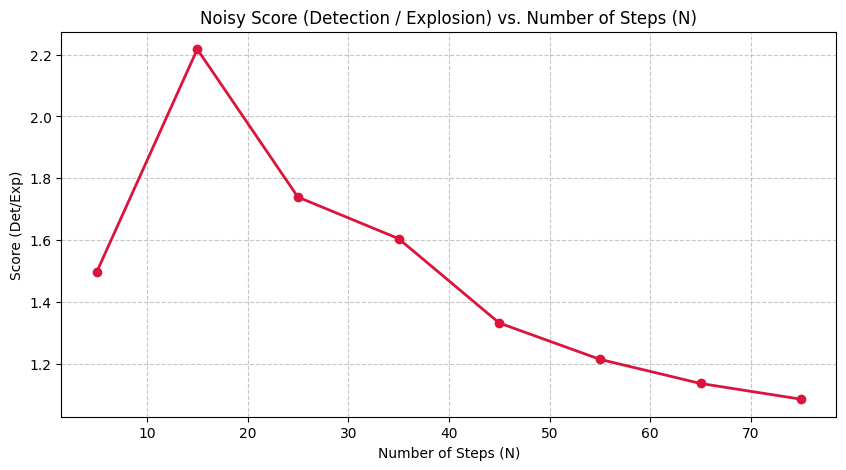

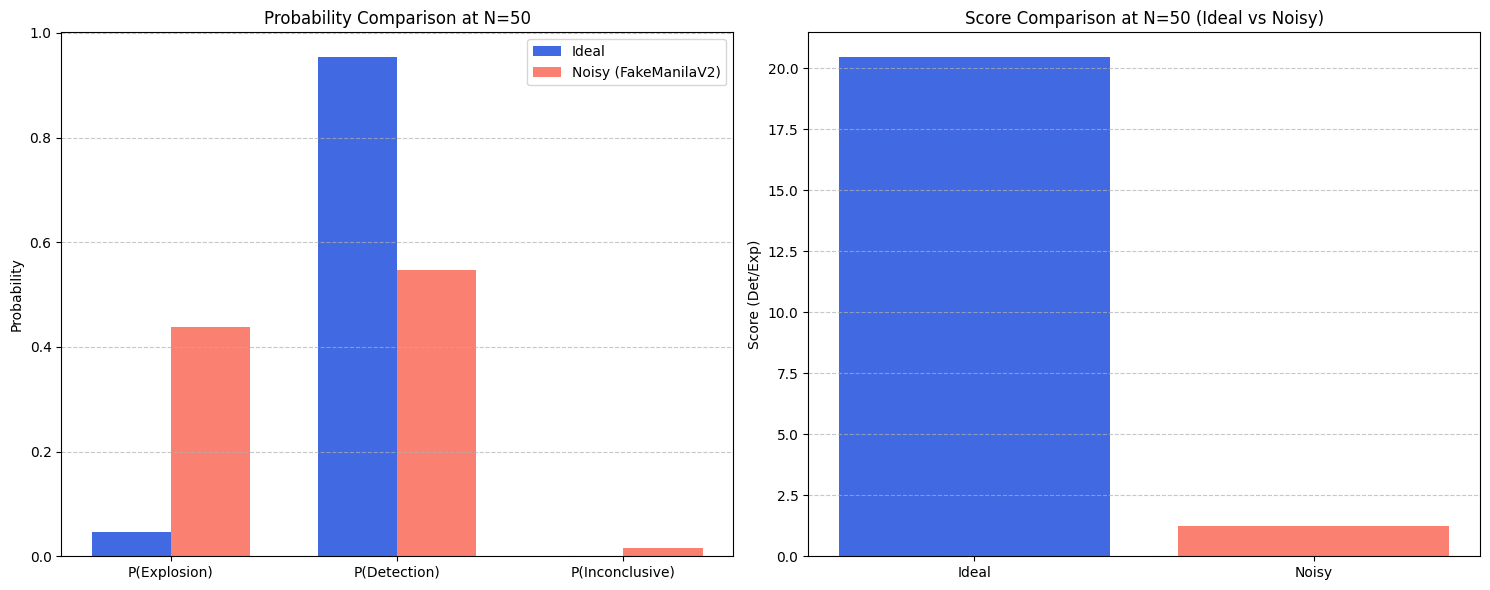

In [ ]:
#Objective 1.4 Study how the score changes when noise is added to your circuit.

import matplotlib.pyplot as plt

# 1. Scaling N from 5 to 75 (steps of 10)
N_values = list(range(5, 76, 10))
noisy_scores = []

print("Evaluating noisy performance for different N steps:")
for N in N_values:
    counts = run_chain_circuit_with_noise(N=N, bomb=True, shots=5000)
    metrics = analyze_results(counts, shots=5000)
    noisy_scores.append(metrics['score'])
    print(f"  N = {N} -> P(Explosion): {metrics['p_explosion']:.4f}, P(Detection): {metrics['p_detection']:.4f}, Score: {metrics['score']:.4f}")

# Plot Noisy Score vs N
plt.figure(figsize=(10, 5))
plt.plot(N_values, noisy_scores, marker='o', linestyle='-', color='crimson', linewidth=2)
plt.title("Noisy Score (Detection / Explosion) vs. Number of Steps (N)")
plt.xlabel("Number of Steps (N)")
plt.ylabel("Score (Det/Exp)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# 2. Detailed comparison at N = 50
shots_compare = 10000
ideal_n50 = analyze_results(run_chain_circuit(N=50, bomb=True, shots=shots_compare), shots_compare)
noisy_n50 = analyze_results(run_chain_circuit_with_noise(N=50, bomb=True, shots=shots_compare), shots_compare)

categories = ['P(Explosion)', 'P(Detection)', 'P(Inconclusive)']
ideal_probs = [ideal_n50['p_explosion'], ideal_n50['p_detection'], ideal_n50['p_inconclusive']]
noisy_probs = [noisy_n50['p_explosion'], noisy_n50['p_detection'], noisy_n50['p_inconclusive']]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Probability comparison bar chart
ax[0].bar(x - width/2, ideal_probs, width, label='Ideal', color='royalblue')
ax[0].bar(x + width/2, noisy_probs, width, label='Noisy (FakeManilaV2)', color='salmon')
ax[0].set_ylabel('Probability')
ax[0].set_title('Probability Comparison at N=50')
ax[0].set_xticks(x)
ax[0].set_xticklabels(categories)
ax[0].legend()
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

# Score comparison
scores = [ideal_n50['score'] if ideal_n50['score'] != float('inf') else 100, noisy_n50['score']]
score_labels = ['Ideal (Score: inf)', f"Noisy (Score: {noisy_n50['score']:.2f})"]
ax[1].bar(['Ideal', 'Noisy'], [min(ideal_n50['score'], 150) if ideal_n50['score'] != float('inf') else 100, noisy_n50['score']], color=['royalblue', 'salmon'])
ax[1].set_ylabel('Score (Det/Exp)')
ax[1].set_title('Score Comparison at N=50 (Ideal vs Noisy)')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [ ]:
#TRACK 2
#• Extend the single-cell bomb tester to probe multiple cells at once, for example rows and columns of
#a grid.
#• Use the radar to find every ship on a board, and report how many ships were detected and how
#many were hit.

def step(qc, path_qubit, target_qubit,tita, bomb)    #This function represents the repititive part of the circuit
  qc.ry(2*tita, path_qubit)
  if bomb:
    qc.cx(path_qubit, target_qubit)

def single_bomb_tester(bomb, theta=np.pi / 2):
    qc = QuantumCircuit(2, 2)         # qubit0 = path, qubit1 = bomb
    qc.ry(theta, 0)                   # enter beamsplitter
    if has_bomb:
        qc.cx(0, 1)
    qc.ry(theta, 0)                   # exit beamsplitter
    qc.measure([0, 1], [0, 1])
    return qc

def row_chain_measure(row):
  N= len(row)
  tita = np.pi/2*N

  qc= QuantumCircuit(N+1, N+1)
  path =0
  for i, bomb in enumerate(row):
    cell_qubit = i + 1
    step(qc, path, cell_qubit, tita, bomb)

  qc.measure(range(N+1),range(N+1))
  return qc

def result(bitstring, N):
  bits=bitstring[::-1]
  path_bit = bits[0]
  cell_bits=bits[1:N+1]

  if '1' in cell_bits:
    return 'hit', cell_bits.index('1')
  elif path_bit=='0':
    return 'detect', None
  else:
    return 'inconclusive', None



